# Ray casting and point location

Two batch queries on a mesh, both returning arrays:

- `cast_rays` shoots rays at a **surface** and reports the nearest hit of each (distance, point, unit normal and the input cell hit);
- `locate_points` finds the **cell** of a volume mesh that contains each point, with the containing simplex's nodes and barycentric weights, by the same search `interpolate` runs.

The CLI forms are `meshioplusplus cast-rays surface.stl origins.ply hits.vtu --direction 0,0,-1` and `meshioplusplus locate volume.vtu points.ply located.vtu`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

rng = np.random.default_rng(7)

## Rays at a sphere

A pinhole camera at `(0, 0, 4)` looks at a unit sphere. Every pixel is a ray, and the hit distance of a triangulated sphere agrees with the analytic distance `d·c - sqrt((d·c)² - |c|² + r²)` up to the facets' sagitta.

rays 25600 hits 12908
max |distance - analytic| = 0.01709056459152647  (a facet is inscribed in the sphere)


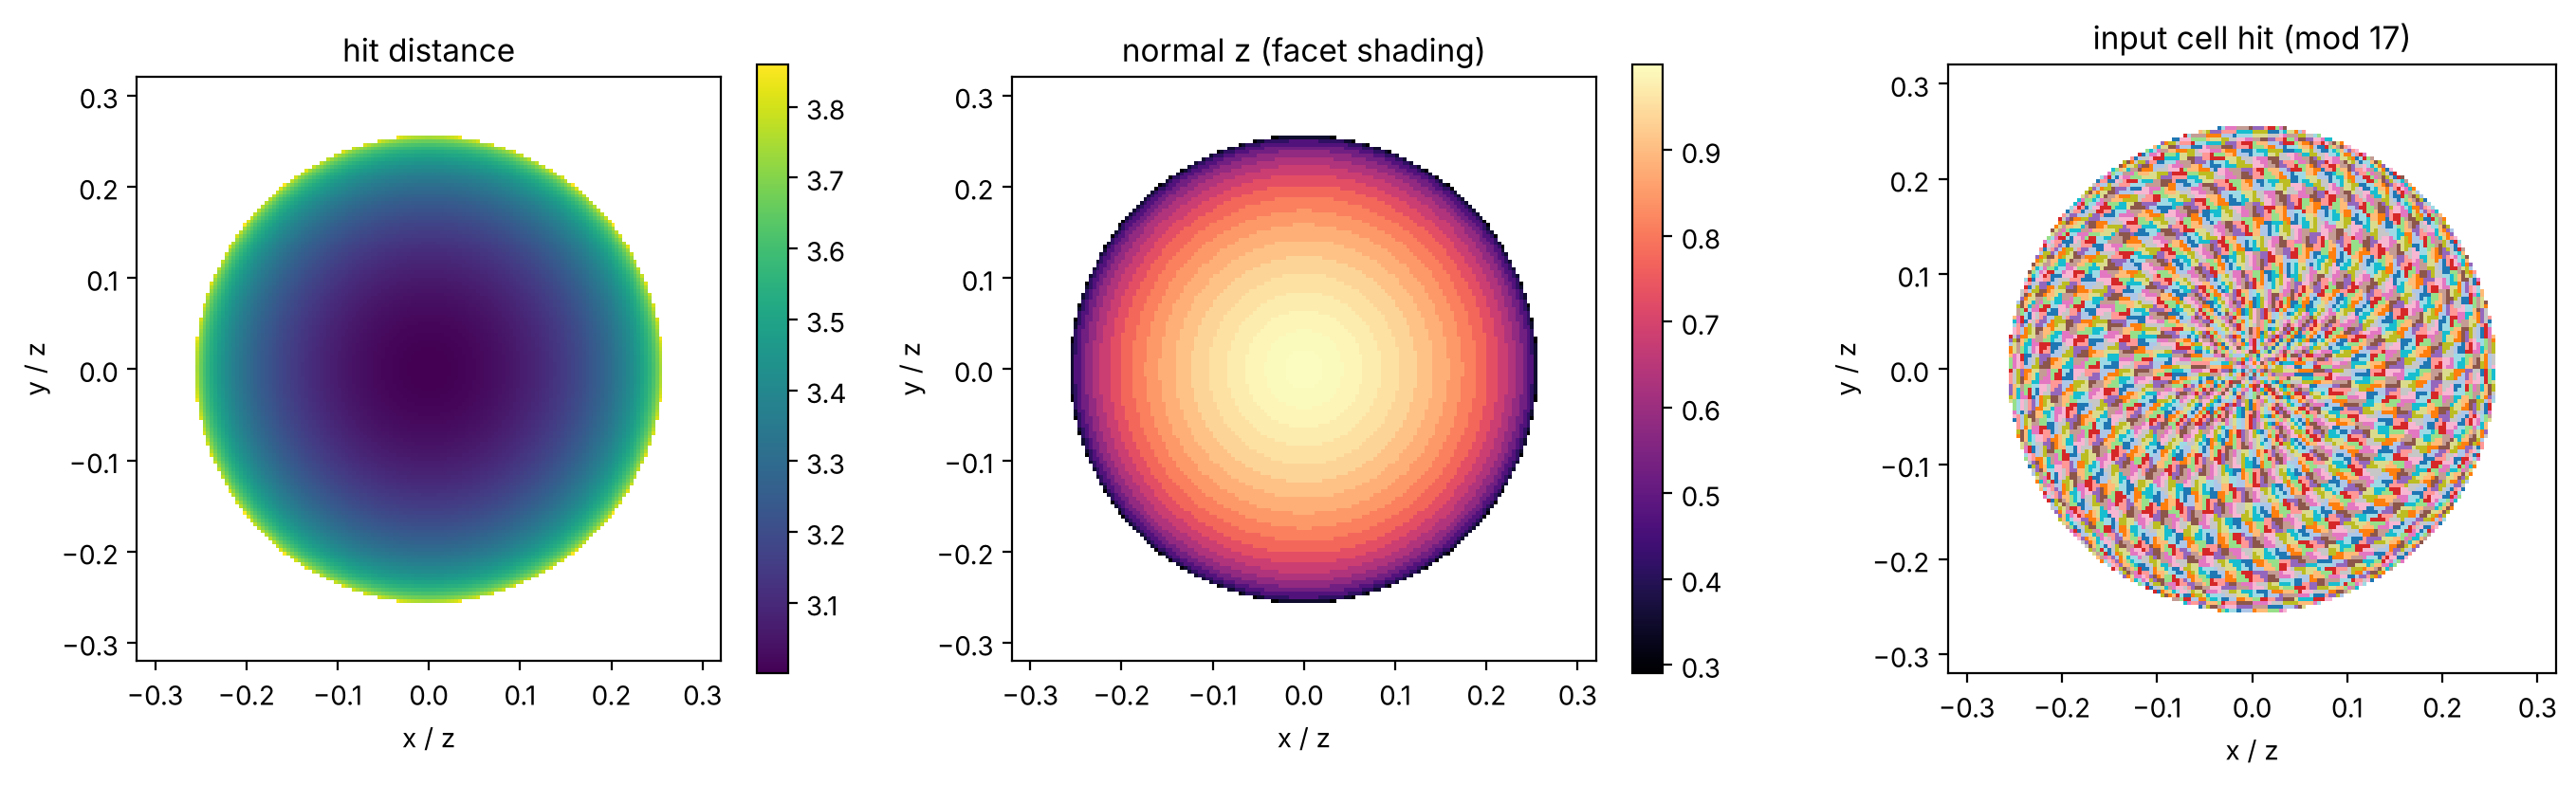

In [2]:
sphere = mp.uv_sphere(1.0, 96, 48)
eye = np.array([0.0, 0.0, 4.0])
n = 160
u = np.linspace(-0.32, 0.32, n)
gx, gy = np.meshgrid(u, u)
dirs = np.stack([gx.ravel(), gy.ravel(), -np.ones(n * n)], axis=1)
dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)

r = mp.cast_rays(sphere, np.broadcast_to(eye, dirs.shape), dirs)
print('rays', n * n, 'hits', r['num_hits'])

# analytic ray-sphere distance for the rays that hit
b = dirs @ eye
disc = b * b - eye @ eye + 1.0
exact = np.where(disc >= 0, -b - np.sqrt(np.maximum(disc, 0)), np.nan)
hit = r['hit']
err = np.abs(r['distance'][hit] - exact[hit])
print('max |distance - analytic| =', err.max(), ' (a facet is inscribed in the sphere)')

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
d = np.where(hit, r['distance'], np.nan).reshape(n, n)
im = ax[0].imshow(d, extent=[u[0], u[-1], u[0], u[-1]], origin='lower', cmap='viridis')
ax[0].set_title('hit distance'); plt.colorbar(im, ax=ax[0])
nz = np.where(hit, r['normal'][:, 2], np.nan).reshape(n, n)
im = ax[1].imshow(nz, extent=[u[0], u[-1], u[0], u[-1]], origin='lower', cmap='magma')
ax[1].set_title('normal z (facet shading)'); plt.colorbar(im, ax=ax[1])
cell = np.where(hit, r['cell'] % 17, np.nan).reshape(n, n)
ax[2].imshow(cell, extent=[u[0], u[-1], u[0], u[-1]], origin='lower', cmap='tab20')
ax[2].set_title('input cell hit (mod 17)')
for a in ax:
    a.set_xlabel('x / z'); a.set_ylabel('y / z')
plt.tight_layout(); plt.show()

## Seams, limits and regions

A ray through a shared edge or vertex hits once. A distance limit drops far hits, and `region` restricts the surface to a named cell region.

In [3]:
cube = mp.box(dims=(1, 1, 1))
skin = mp.extract_surface(cube)
rays = mp.cast_rays(skin, [[-1, 0.5, 0.5], [-1, 0.0, 0.0], [-1, 0.5, 0.0]], [1, 0, 0])
print('through a face diagonal, a vertex and an edge:', rays['distance'])
print('with max_distance=0.5:', mp.cast_rays(skin, [[-1, 0.5, 0.5]], [1, 0, 0], max_distance=0.5)['num_hits'], 'hits')

through a face diagonal, a vertex and an edge: [1. 1. 1.]
with max_distance=0.5: 0 hits


## Which cell is a point in?

`locate_points` returns the input cell, the four nodes of the containing simplex and its barycentric weights. The weights reproduce the point and interpolate any point array, bit for bit as `interpolate` does.

located 4000 of 4000
max |sum(w x_nodes) - point| = 3.3306690738754696e-16
identical to interpolate: True


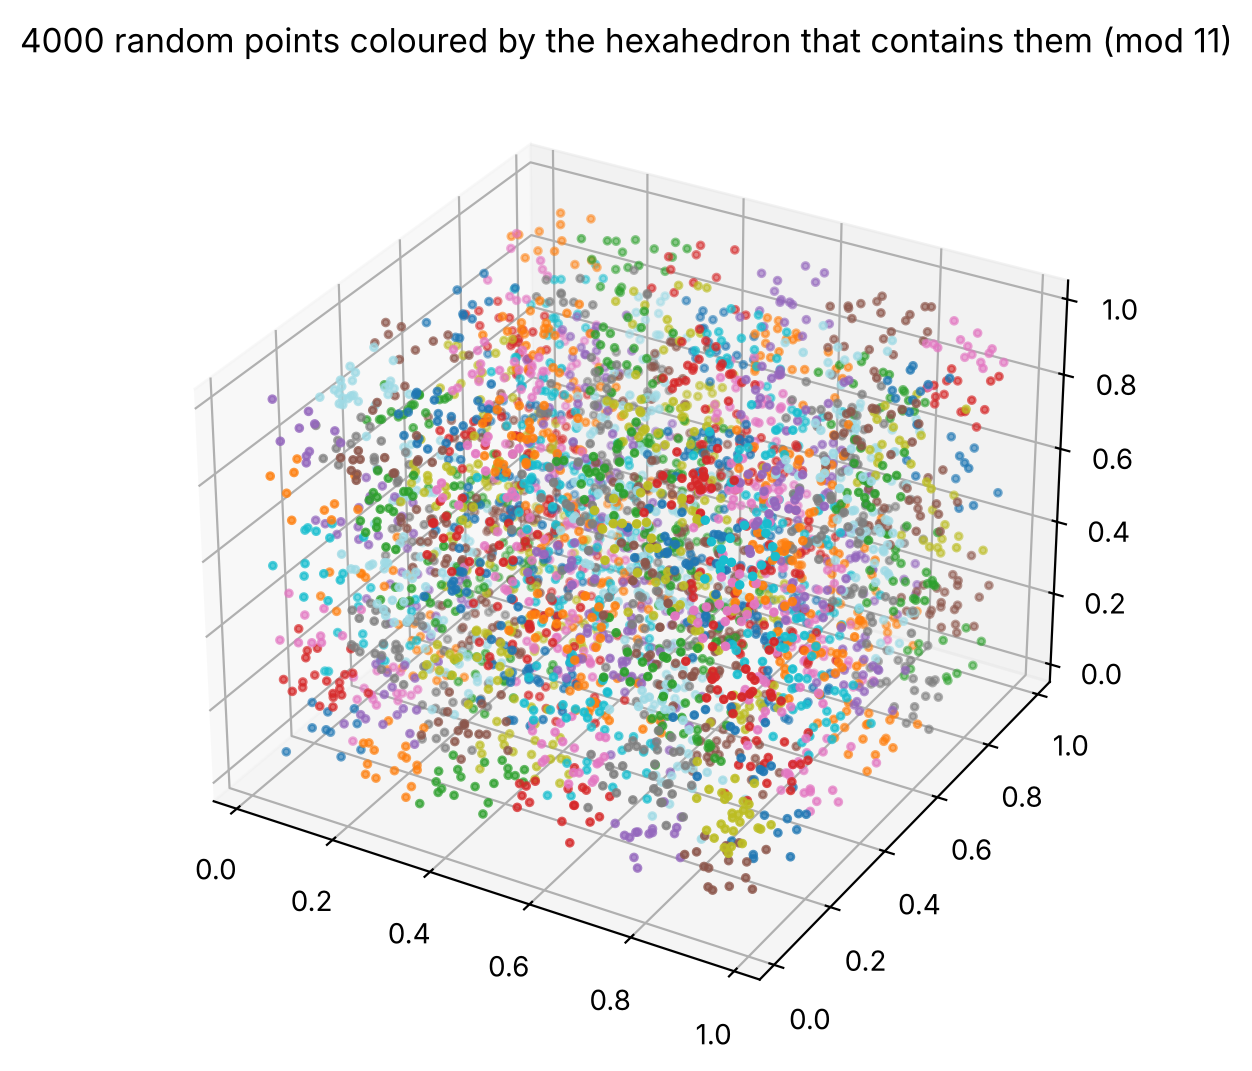

In [4]:
vol = mp.box(dims=(6, 6, 6), size=(1.0, 1.0, 1.0))
pts = np.asarray(vol.points)
field = np.sin(4 * pts[:, 0]) + pts[:, 1] ** 2 - pts[:, 2]
vol.point_data['f'] = field
q = rng.uniform(0.02, 0.98, size=(4000, 3))

loc = mp.locate_points(vol, q)
print('located', loc['num_located'], 'of', len(q))
w, nodes = loc['barycentric'], loc['nodes']
valid = nodes >= 0
rec = np.einsum('nk,nkd->nd', np.where(valid, w, 0.0), pts[np.where(valid, nodes, 0)])
print('max |sum(w x_nodes) - point| =', np.abs(rec - q).max())

via_weights = np.array([sum(wi * field[ni] for wi, ni in zip(wr, nr) if ni >= 0) for wr, nr in zip(w, nodes)])
target = mp.Mesh(q, [('vertex', np.arange(len(q)).reshape(-1, 1))])
via_interp = mp.interpolate(vol, target, method='barycentric').point_data['f']
print('identical to interpolate:', np.array_equal(via_weights, via_interp))

fig = plt.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(projection='3d')
sc = ax.scatter(*q.T, c=loc['cell'] % 11, cmap='tab20', s=6)
ax.set_title('4000 random points coloured by the hexahedron that contains them (mod 11)')
plt.tight_layout(); plt.show()